# Participant table: overview

What this notebook shows: the participant master table (one row per LEMON participant) and the data available per participant. **Only group-level numbers are printed**: no participant rows or IDs, so this notebook is safe to share.

It reads the outputs of the three scripts in `scripts/`. Run them first; the README has the commands.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())   # works from any folder
RES = ROOT / "analysis/participant_table/results"
master = pd.read_csv(ROOT / "data/derived/participant_table/master_table_with_flags.csv", dtype=str)
print(f"master table: {master.shape[0]} participants x {master.shape[1]} columns")

master table: 228 participants x 67 columns


## 1. What is in the table
One line per column: where it comes from and how many participants have a value.

In [2]:
dd = pd.read_csv(ROOT / "analysis/participant_table/results/data_dictionary.csv")
filled = master.notna().sum().rename("n_with_value")
dd.set_index("column")[["type", "meaning"]].join(filled).fillna({"n_with_value": "(flag column)"}).head(60)

,type,meaning,n_with_value
column,,,
participant_id,derived,Participant ID in BIDS form (prefix sub- plus ...,228
in_META_file,derived,yes if ID appears in the META file; no otherwise,228
age_bin_text,raw,"Age as 5-year bin text, e.g. 20-25. Not an exa...",227
age_bin_midpoint_years,derived,"MIDPOINT of the bin (lower+upper)/2, e.g. 20-2...",227
sex_coded_1female_2male,raw,"Sex code as in file: 1 = female, 2 = male",227
sex_label,derived,female/male label from the code above,227
education,raw,School level (free text as in file),227
handedness,raw,right / left / ambidextrous (as in file),227
height_cm,raw,Body height in cm (Day 1),227


## 2. Who the participants are
Age is only given in 5-year bins. Nobody is between 40 and 55: LEMON recruited a younger and an older group.

sex_label,female,male
age_bin_text,,
20-25,25,54
25-30,14,46
30-35,6,7
35-40,0,1
55-60,2,2
60-65,7,12
65-70,16,9
70-75,10,12
75-80,2,2


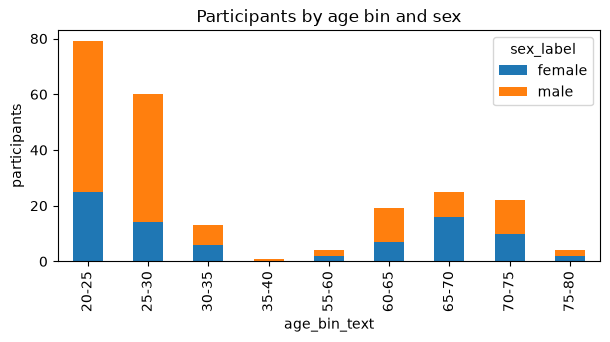

,variable,value,n
13,handedness,(missing),1
14,handedness,ambedextor,1
15,handedness,ambidextrous,3
16,handedness,left,21
17,handedness,right,202
18,Smoking,(missing),1
19,Smoking,non-smoker,190
20,Smoking,occasional smoker,21
21,Smoking,smoker,15
22,Smoking,smoker?,1


In [3]:
cat = pd.read_csv(RES / "categorical_counts.csv")
ages = master.pivot_table(index="age_bin_text", columns="sex_label", values="participant_id", aggfunc="count", fill_value=0)
display(ages)
ages.plot.bar(stacked=True, figsize=(7, 3), title="Participants by age bin and sex"); plt.ylabel("participants"); plt.show()
cat[cat.variable.isin(["handedness", "Smoking"])]

## 3. What data is available
Flags come from the LEMON availability tables (1 = listed as available). They do not prove the files exist; that is checked per modality (e.g. `fmri_eda`).

In [4]:
flags = pd.read_csv(RES / "availability_flag_counts.csv")
display(flags[["flag", "available_1", "not_available_0", "not_in_table_blank"]])
display(pd.read_csv(RES / "availability_counts.csv"))

,flag,available_1,not_available_0,not_in_table_blank
0,has_cardiac_flag,213,14,1
1,has_fmri_rest_flag,226,1,1
2,d1_blood_pressure_beat_to_beat_flag,143,84,1
3,d1_pulse_photoplethysmography_flag,143,84,1
4,d1_respiration_flag,162,65,1
5,fu_ecg_any,98,130,0
6,fu_bpp_any,102,126,0
7,fu_ppg_any,102,126,0
8,fu_resp_any,98,130,0
9,fu_any_ses2_physio,109,119,0


,group,n,with_PSQ,with_TICS,with_PSQ_and_TICS
0,all,228,220,220,220
1,ECG_flag,213,207,207,207
2,rsfMRI_flag,226,219,219,219
3,ECG_and_rsfMRI,212,206,206,206


In [5]:
pd.read_csv(RES / "ecg_frmi_psq_by_age_sex.csv").pivot(index="age_bin", columns="sex", values="n_ECG_and_rsfMRI_and_PSQ").fillna(0).astype(int)

sex,female,male
age_bin,,
20-25,22,50
25-30,12,45
30-35,6,6
35-40,0,1
55-60,2,2
60-65,5,12
65-70,12,9
70-75,8,10
75-80,2,2


## 4. Main measures, younger vs older
Mean, SD and range per group (from `results/descriptives.csv`).

In [6]:
desc = pd.read_csv(RES / "descriptives.csv")
key = ["bmi_kg_per_m2", "BP1_left_systole", "STAI_Trait_Anxiety", "PSQ_OverallScore", "TICS_ScreeningScale", "AUDIT"]
desc[desc.variable.isin(key)].pivot(index="variable", columns="group", values=["n", "mean", "std"]).round(1)

n                                 mean                                 std                              
group                  all older (55-80) younger (20-40)    all older (55-80) younger (20-40)   all older (55-80) younger (20-40)
variable                                                                                                                         
AUDIT                219.0          72.0           147.0    4.8           3.1             5.6   3.8           2.5             4.0
BP1_left_systole     225.0          73.0           152.0  134.1         152.5           125.3  19.7          17.8            13.6
PSQ_OverallScore     220.0          72.0           148.0   30.1          23.8            33.2  15.5          13.5            15.5
STAI_Trait_Anxiety   220.0          72.0           148.0   36.3          33.1            37.8   8.6           7.8             8.6
TICS_ScreeningScale  220.0          72.0           148.0   13.3          10.7            14.5   8.5           7.1             8.9
bmi_kg_per_m2        227.0          74.0           153.0   24.2          26.8            23.0   3.6           3.9             2.8

## 5. Missing values
Columns with the most missing values (over 20% is flagged in `results/missingness.csv`).

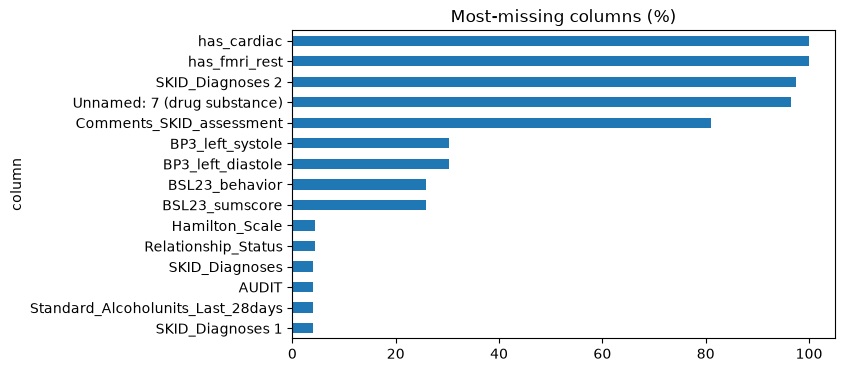

In [7]:
miss = pd.read_csv(RES / "missingness.csv").sort_values("missing_pct", ascending=False).head(15)
miss.plot.barh(x="column", y="missing_pct", figsize=(7, 4), legend=False, title="Most-missing columns (%)"); plt.gca().invert_yaxis(); plt.show()